# Alpha4: missões sustentáveis por contexto municipal

**FIAP · Artificial Intelligence & Chatbot · Sprint 4 · Turma 1TDSPW**

Vinicius de Oliveira (561862), Robison Custodio Junior (572866), Lucas Fernando Silva (564848), Thiago Shimizu Sodré dos Santos (572867) e Arthur Mendes Garcia (571703).

O objetivo é **agrupar municípios por indicadores ambientais**, comparando K-Means e Gaussian Mixture. Os grupos orientam categorias de missões da Soul Up por regras explícitas. Não há rótulos de missão aceita, nem previsão de engajamento individual.

A cópia compactada abaixo é o CSV original fornecido pelo grupo, não dados sintéticos. O notebook contém todo o código de preparação, treinamento, avaliação, serialização e API; não precisa dos módulos `.py` do repositório.

## Como executar

Use Python 3.12 e um kernel com as dependências abaixo. Em um terminal, na pasta dos quatro arquivos:

```text
python -m venv .venv
.venv\Scripts\python -m pip install numpy==2.5.4 pandas==3.1.0 scikit-learn==1.9.1 Flask==3.1.3 joblib==1.6.0 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.4.0 matplotlib==3.11.2
```

Selecione esse ambiente no editor de notebooks e execute todas as células, em ordem. Não instale pacotes automaticamente ao executar o notebook. A API já funciona com o modelo entregue, sem executar o treinamento novamente.

Dados: SINISA, ano ambiental 2023, com cadastro municipal do IBGE. Fontes informadas na Sprint 3: [resultados SINISA](https://www.gov.br/cidades/pt-br/acesso-a-informacao/acoes-e-programas/saneamento/sinisa/resultados-sinisa) e [API de localidades IBGE](https://servicodados.ibge.gov.br/api/docs/localidades). A base tem viés de resposta municipal e não representa os municípios excluídos por ausência ou inconsistência dos dados.

In [1]:
import base64
import gzip
import hashlib
from pathlib import Path

CSV_COMPACTADO = '...'
SHA256_ESPERADO = '92f211fd1d0ffe4e31499f55ad001ac94438e94321345ca2b17d1763cfbc0564'
arquivo = Path('alpha4_sinisa_ibge_municipios.csv')
conteudo = gzip.decompress(base64.b64decode(CSV_COMPACTADO))
assert hashlib.sha256(conteudo).hexdigest() == SHA256_ESPERADO
if arquivo.exists():
    assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == SHA256_ESPERADO, 'CSV local difere da base fornecida; preserve-o em outra pasta antes de executar.'
else:
    arquivo.write_bytes(conteudo)
print('Base original verificada. SHA-256:', SHA256_ESPERADO)

Base original verificada. SHA-256: 92f211fd1d0ffe4e31499f55ad001ac94438e94321345ca2b17d1763cfbc0564


## 1. Base real e qualidade

São 4.775 municípios e 31 colunas. Códigos e nomes são contexto, não medidas de distância. Não usamos os indicadores binários derivados nem o gap entre coberturas, para evitar redundância. Escolhemos oito indicadores numéricos do dicionário. A inspeção de consistência não comprova exatidão dos valores declarados por cada município.

In [2]:
"""Leitura da base original, sem criar rótulos artificiais."""

from pathlib import Path

import numpy as np
import pandas as pd

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
ARQUIVO_DADOS = BASE / 'alpha4_sinisa_ibge_municipios.csv'
SEMENTE = 42

# Identificadores, binários derivados e o gap redundante ficam fora das distâncias.
FEATURES = [
    'taxa_urbanizacao_pct',
    'densidade_populacional_hab_km2',
    'cobertura_coleta_residuos_pct',
    'cobertura_coleta_seletiva_pct',
    'pontos_entrega_voluntaria_por_mil_hab',
    'massa_residuos_urbanos_kg_hab_dia',
    'disposicao_final_inadequada_pct',
    'recuperacao_reciclaveis_pct',
]
LOG_FEATURES = [
    'densidade_populacional_hab_km2',
    'pontos_entrega_voluntaria_por_mil_hab',
    'massa_residuos_urbanos_kg_hab_dia',
]
PERCENTUAIS = [nome for nome in FEATURES if nome.endswith('_pct')]


def carregar_dados(caminho=ARQUIVO_DADOS):
    dados = pd.read_csv(caminho, dtype={'codigo_ibge': str})
    obrigatorias = ['codigo_ibge', 'municipio', 'uf', 'regiao', *FEATURES]
    if not set(obrigatorias).issubset(dados.columns):
        raise ValueError('A base não contém as colunas necessárias.')
    if dados[obrigatorias].isna().any().any():
        raise ValueError('Há campos obrigatórios ausentes na base.')
    if dados.codigo_ibge.duplicated().any():
        raise ValueError('Há códigos IBGE duplicados.')
    if not dados.codigo_ibge.str.fullmatch(r'[0-9]{7}').all():
        raise ValueError('Código IBGE deve ter sete dígitos.')
    valores = dados[FEATURES].to_numpy(dtype=float)
    if not np.isfinite(valores).all() or (valores < 0).any():
        raise ValueError('Indicadores devem ser números finitos não negativos.')
    if (dados[PERCENTUAIS] > 100).any().any():
        raise ValueError('Percentuais devem estar entre zero e cem.')
    if (dados.cobertura_coleta_seletiva_pct > dados.cobertura_coleta_residuos_pct).any():
        raise ValueError('Coleta seletiva não pode superar a cobertura total.')
    return dados

In [3]:
from IPython.display import display, Markdown

dados = carregar_dados()
display(dados[['municipio', 'uf', *FEATURES]].head())
display(dados[FEATURES].describe().round(3))
print('Dimensão:', dados.shape)
print('Ausentes:', dados.isna().sum().sum(), '| Códigos duplicados:', dados.codigo_ibge.duplicated().sum())
print('Ano:', dados.ano_referencia_sinisa.unique(), '| UFs:', dados.uf.nunique())

,municipio,uf,taxa_urbanizacao_pct,densidade_populacional_hab_km2,cobertura_coleta_residuos_pct,cobertura_coleta_seletiva_pct,pontos_entrega_voluntaria_por_mil_hab,massa_residuos_urbanos_kg_hab_dia,disposicao_final_inadequada_pct,recuperacao_reciclaveis_pct
0,Alta Floresta D'Oeste,RO,57.27,3.07,59.15,0.00,0.05,0.54,0.0,0.00
1,Ariquemes,RO,84.70,22.10,80.95,80.95,0.01,0.47,0.0,17.13
2,Cabixi,RO,42.65,4.11,100.00,0.00,0.00,0.29,0.0,0.00
3,Cacoal,RO,78.81,23.14,78.81,16.18,0.00,0.66,0.0,9.06
4,Cerejeiras,RO,84.67,5.77,84.67,84.67,0.00,0.56,0.0,9.03


,taxa_urbanizacao_pct,densidade_populacional_hab_km2,cobertura_coleta_residuos_pct,cobertura_coleta_seletiva_pct,pontos_entrega_voluntaria_por_mil_hab,massa_residuos_urbanos_kg_hab_dia,disposicao_final_inadequada_pct,recuperacao_reciclaveis_pct
count,4775.000,4775.000,4775.000,4775.000,4775.000,4775.000,4775.000,4775.000
mean,65.024,129.549,79.064,18.086,0.098,0.812,37.144,2.965
std,22.010,646.459,22.264,33.567,0.731,0.867,47.625,7.754
min,4.180,0.160,10.100,0.000,0.000,0.020,0.000,0.000
25%,48.370,11.815,62.780,0.000,0.000,0.410,0.000,0.000
50%,66.310,25.110,86.670,0.000,0.000,0.660,0.000,0.000
75%,83.720,56.000,99.040,12.535,0.000,1.010,100.000,1.610
max,100.000,13550.910,100.000,100.000,45.150,43.590,100.000,96.630


Dimensão: (4775, 31)
Ausentes: 0 | Códigos duplicados: 0
Ano: [2023] | UFs: 27


## 2. Preparação sem vazamento e comparação dos dois modelos

Separamos os municípios em treino (60%), validação (20%) e teste (20%), com semente 42 e estratificação pela grande região. A região só preserva representação nas partições; não entra no cálculo de distâncias. Não há divisão temporal: o único ano ambiental disponível é 2023.

Aplicamos `log1p` a densidade, pontos de entrega por mil habitantes e massa de resíduos, por suas caudas longas; percentuais preservam a escala original até a padronização. `StandardScaler` aprende médias e desvios somente do treino. Não excluímos valores extremos legítimos.

**K-Means** é a referência simples baseada em distância a centros. **Gaussian Mixture** permite covariâncias completas e grupos com formatos distintos. Ambos possuem `predict`, útil para a API. Comparamos k de 2 a 6. Para evitar selecionar partições com um grupo residual, exigimos convergência e pelo menos 2% da validação em cada grupo, um critério de projeto definido antes da avaliação.

Selecionamos pela maior silhouette na validação. Também relatamos Davies-Bouldin (menor é melhor) e Calinski-Harabasz (maior é melhor). Essas são métricas internas de geometria, não acurácia nem utilidade comprovada das missões. Silhouette favorece grupos compactos, o que pode favorecer K-Means; não é uma avaliação neutra de todos os objetivos possíveis.

In [4]:
"""Pipelines e comparação de agrupamentos sem usar identificadores nas distâncias."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.mixture import GaussianMixture
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler



def separar_dados(dados):
    treino, restante = train_test_split(
        dados, test_size=0.4, random_state=SEMENTE, stratify=dados.regiao,
    )
    validacao, teste = train_test_split(
        restante, test_size=0.5, random_state=SEMENTE, stratify=restante.regiao,
    )
    return treino.copy(), validacao.copy(), teste.copy()


def criar_preparo():
    # log1p comprime caudas longas sem remover observações nem alterar percentuais.
    transformar = ColumnTransformer([
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), LOG_FEATURES),
        ('percentuais', 'passthrough', PERCENTUAIS),
    ], remainder='drop')
    return Pipeline([('transformar', transformar), ('escalonar', StandardScaler())])


def criar_kmeans(k):
    return Pipeline([
        ('preparo', criar_preparo()),
        ('modelo', KMeans(n_clusters=k, n_init=20, random_state=SEMENTE)),
    ])


def criar_mistura(k):
    return Pipeline([
        ('preparo', criar_preparo()),
        ('modelo', GaussianMixture(
            n_components=k, covariance_type='full', n_init=5,
            max_iter=500, reg_covar=1e-5, random_state=SEMENTE,
        )),
    ])


def medir_grupos(pipeline, dados, k):
    valores = pipeline.named_steps['preparo'].transform(dados[FEATURES])
    grupos = pipeline.predict(dados[FEATURES])
    contagens = np.bincount(grupos, minlength=k)
    resultado = {
        'tamanhos': contagens.tolist(),
        'menor_proporcao': float(contagens.min() / len(dados)),
        'silhouette': None, 'davies_bouldin': None, 'calinski_harabasz': None,
    }
    if 1 < len(np.unique(grupos)) < len(grupos):
        resultado.update({
            'silhouette': float(silhouette_score(valores, grupos)),
            'davies_bouldin': float(davies_bouldin_score(valores, grupos)),
            'calinski_harabasz': float(calinski_harabasz_score(valores, grupos)),
        })
    return resultado


def comparar_modelos(treino, validacao):
    linhas, candidatos = [], {}
    for nome, construir in [('kmeans', criar_kmeans), ('mistura_gaussiana', criar_mistura)]:
        for k in range(2, 7):
            pipeline = construir(k).fit(treino[FEATURES])
            metricas = medir_grupos(pipeline, validacao, k)
            convergiu = bool(getattr(pipeline.named_steps['modelo'], 'converged_', True))
            linhas.append({
                'modelo': nome, 'k': k, 'convergiu': convergiu,
                **{campo: valor for campo, valor in metricas.items() if campo != 'tamanhos'},
                'elegivel': convergiu and metricas['menor_proporcao'] >= 0.02,
            })
            candidatos[(nome, k)] = pipeline
    tabela = pd.DataFrame(linhas).sort_values('silhouette', ascending=False)
    if not tabela.elegivel.any():
        raise ValueError('Nenhum candidato convergiu com ao menos 2% em cada grupo de validação.')
    return tabela, candidatos


def avaliar_finalistas(tabela, candidatos, teste):
    # A seleção usa somente validação; teste é observado após fixar os finalistas.
    finalistas = tabela[tabela.elegivel].groupby('modelo', sort=False).head(1)
    resultados = {}
    for linha in finalistas.itertuples():
        resultados[linha.modelo] = {
            'k': int(linha.k),
            **medir_grupos(candidatos[(linha.modelo, linha.k)], teste, linha.k),
        }
    vencedor = tabela[tabela.elegivel].iloc[0]
    return str(vencedor.modelo), int(vencedor.k), resultados

## 3. Perfis e regras auditáveis

Os nomes dos grupos descrevem suas médias observadas, sem inventar rótulos sociais. Os limiares de 30% para cobertura seletiva, 5% para recuperação, 1 kg/habitante/dia e 50% para disposição inadequada são **heurísticas de projeto**, não parâmetros aprendidos ou padrões oficiais. São pontos de partida a validar com especialistas e usuários.

A presença de PEV no perfil não garante sua existência em cada município. A API filtra missões de entrega voluntária quando o indicador municipal informado é zero. Endereços, materiais aceitos e funcionamento precisam de confirmação local.

In [5]:
"""Heurísticas explícitas: os modelos aprendem grupos, não a eficácia das missões."""


# Limiares de projeto, não verdades científicas nem parâmetros aprendidos.
REGRAS = [
    {'feature': 'cobertura_coleta_seletiva_pct', 'operador': '<', 'limiar': 30,
     'categoria': 'reducao_e_reutilizacao',
     'orientacao': 'Reduza descartáveis e reutilize materiais limpos e seguros.'},
    {'feature': 'recuperacao_reciclaveis_pct', 'operador': '<', 'limiar': 5,
     'categoria': 'separacao_e_educacao',
     'orientacao': 'Aprenda a separar recicláveis e compartilhe orientações locais verificadas.'},
    {'feature': 'pontos_entrega_voluntaria_por_mil_hab', 'operador': '>', 'limiar': 0,
     'categoria': 'entrega_voluntaria',
     'orientacao': 'Consulte endereço, materiais aceitos e funcionamento de ponto de entrega oficial.'},
    {'feature': 'massa_residuos_urbanos_kg_hab_dia', 'operador': '>', 'limiar': 1,
     'categoria': 'consumo_consciente',
     'orientacao': 'Planeje compras e evite descartáveis desnecessários.'},
    {'feature': 'disposicao_final_inadequada_pct', 'operador': '>', 'limiar': 50,
     'categoria': 'descarte_responsavel',
     'orientacao': 'Busque informações oficiais de coleta e descarte; não entre em áreas de disposição.'},
]


def associar_missoes(perfis):
    for perfil in perfis.values():
        recomendacoes = []
        for regra in REGRAS:
            valor = perfil['medias'][regra['feature']]
            atende = valor < regra['limiar'] if regra['operador'] == '<' else valor > regra['limiar']
            if atende:
                recomendacoes.append({
                    'categoria': regra['categoria'], 'orientacao': regra['orientacao'],
                    'motivo_grupo': f"Média de {regra['feature']}: {valor:.2f}; regra {regra['operador']} {regra['limiar']}.",
                })
        if not recomendacoes:
            recomendacoes.append({
                'categoria': 'consumo_consciente',
                'orientacao': 'Planeje compras e evite descartáveis desnecessários.',
                'motivo_grupo': 'Sugestão geral quando nenhum limiar específico é atendido.',
            })
        perfil['recomendacoes'] = recomendacoes
    return perfis


def descrever_grupos(pipeline, dados):
    grupos = dados[FEATURES].copy()
    grupos['grupo'] = pipeline.predict(dados[FEATURES])
    medias = grupos.groupby('grupo')[FEATURES].mean()
    tamanhos = grupos.groupby('grupo').size()
    return {
        str(grupo): {
            'nome': f'Grupo {grupo}: coleta seletiva média {linha.cobertura_coleta_seletiva_pct:.1f}%',
            'municipios': int(tamanhos.loc[grupo]),
            'medias': {nome: float(linha[nome]) for nome in FEATURES},
        }
        for grupo, linha in medias.iterrows()
    }

## 4. Treinamento, teste reservado e serialização

Cada família fixa seu k pela validação antes de consultar o teste. O vencedor geral também é escolhido apenas pela validação. Depois de avaliar esses pipelines no teste, reajustamos somente o vencedor em toda a base para disponibilização. As métricas de teste não são atribuídas ao reajuste final.

O único arquivo `.joblib` inclui pipeline, perfis, regras, versões, hash da base e catálogo dos indicadores municipais. Isso permite usar a API com somente os quatro arquivos da entrega, sem CSV externo. Carregue apenas o modelo produzido por este projeto e de origem confiável.

In [6]:
"""Treinamento offline; a API apenas carrega o artefato gerado aqui."""

import hashlib
import json
from importlib.metadata import version

import joblib



def executar_treinamento():
    dados = carregar_dados()
    treino, validacao, teste = separar_dados(dados)
    tabela, candidatos = comparar_modelos(treino, validacao)
    nome, k, avaliacao = avaliar_finalistas(tabela, candidatos, teste)
    # Somente depois da avaliação, reajuste em toda a base para disponibilização.
    construir = criar_kmeans if nome == 'kmeans' else criar_mistura
    final = construir(k).fit(dados[FEATURES])
    perfis = associar_missoes(descrever_grupos(final, dados))
    metricas = {
        'semente': SEMENTE,
        'particao': {'treino': len(treino), 'validacao': len(validacao), 'teste': len(teste)},
        'vencedor': {'modelo': nome, 'k': k},
        'candidatos_validacao': tabela.to_dict(orient='records'),
        'finalistas_teste': avaliacao,
        'observacao': 'Métricas de teste são dos pipelines ajustados apenas no treino; o artefato final foi reajustado em toda a base.',
    }
    artefato = {
        'formato': 1, 'pipeline': final, 'modelo': nome, 'k': k,
        'features': FEATURES, 'percentuais': PERCENTUAIS, 'perfis': perfis, 'regras': REGRAS,
        'catalogo': dados[['codigo_ibge', 'municipio', 'uf', *FEATURES]].set_index('codigo_ibge').to_dict(orient='index'),
        'limites_observados': {nome: float(dados[nome].max()) for nome in FEATURES},
        'ano_referencia': 2023, 'metricas': metricas,
        'sha256_base': hashlib.sha256(ARQUIVO_DADOS.read_bytes()).hexdigest(),
        'versoes': {nome: version(nome) for nome in ['numpy', 'pandas', 'scikit-learn', 'Flask', 'joblib']},
    }
    joblib.dump(artefato, BASE / 'modelo_alpha4.joblib', compress=3)
    (BASE / 'metricas.json').write_text(json.dumps(metricas, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    (BASE / 'perfis_grupos.json').write_text(json.dumps(perfis, ensure_ascii=False, indent=2), encoding='utf-8')
    return dados, tabela, artefato

In [7]:
dados, tabela, artefato = executar_treinamento()
display(tabela.round(5))
display(pd.DataFrame(artefato['metricas']['finalistas_teste']).T)
print('Partições:', artefato['metricas']['particao'])
print('Selecionado pela validação:', artefato['modelo'], '| k =', artefato['k'])

,modelo,k,convergiu,menor_proporcao,silhouette,davies_bouldin,calinski_harabasz,elegivel
4,kmeans,6,True,0.03770,0.22725,1.33319,205.00676,True
3,kmeans,5,True,0.03979,0.21617,1.41194,203.18555,True
0,kmeans,2,True,0.45340,0.20404,1.85120,238.18180,True
1,kmeans,3,True,0.22094,0.20023,1.65973,224.55903,True
2,kmeans,4,True,0.21257,0.19853,1.57574,202.70838,True
6,mistura_gaussiana,3,True,0.27120,0.13739,2.11562,141.44022,True
5,mistura_gaussiana,2,True,0.45026,0.13285,2.65656,119.73081,True
7,mistura_gaussiana,4,True,0.12880,0.11773,2.76223,105.37400,True
8,mistura_gaussiana,5,True,0.03770,0.08942,3.10875,80.28008,True
9,mistura_gaussiana,6,True,0.03770,0.06445,3.00238,73.69107,True


,k,tamanhos,menor_proporcao,silhouette,davies_bouldin,calinski_harabasz
kmeans,6,"[257, 225, 242, 39, 42, 150]",0.040838,0.229381,1.336548,203.134689
mistura_gaussiana,3,"[281, 309, 365]",0.294241,0.134549,2.161733,140.742612


Partições: {'treino': 2865, 'validacao': 955, 'teste': 955}
Selecionado pela validação: kmeans | k = 6


### Interpretação da comparação executada

O K-Means com **k=6** apresentou a maior silhouette de validação entre os dez candidatos. Esse k está no limite superior da faixa 2–6 pesquisada: o resultado justifica a escolha dentro desta comparação, mas não demonstra que seis é o número ideal em qualquer cenário.

No teste reservado, a silhouette do K-Means foi **0.22938**, contra **0.13455** da mistura gaussiana com **k=3**. As duas medidas são positivas, mas modestas; há sobreposição importante dos contextos, e não uma separação perfeita. Davies-Bouldin foi **1.33655** para K-Means e **2.16173** para GMM, também favorecendo o primeiro nesta avaliação geométrica.

A flexibilidade de covariâncias do GMM não gerou maior separação por silhouette nesta base. A presença de muitos zeros e indicadores assimétricos pode dificultar a hipótese gaussiana; isso é uma hipótese explicativa, não uma causa demonstrada pelos experimentos. Não relatamos “acertos” de missões, pois não existem rótulos verdadeiros de aceitação para verificá-los.

In [8]:
perfis = pd.DataFrame({grupo: {
    'municipios': perfil['municipios'], **perfil['medias']
} for grupo, perfil in artefato['perfis'].items()}).T
display(perfis.round(3))
display(pd.DataFrame(artefato['regras']))

,municipios,taxa_urbanizacao_pct,densidade_populacional_hab_km2,cobertura_coleta_residuos_pct,cobertura_coleta_seletiva_pct,pontos_entrega_voluntaria_por_mil_hab,massa_residuos_urbanos_kg_hab_dia,disposicao_final_inadequada_pct,recuperacao_reciclaveis_pct
0,1162.0,64.269,25.776,81.833,1.909,0.028,1.022,98.762,0.326
1,1273.0,77.704,289.820,92.033,2.108,0.036,1.002,2.906,0.562
2,225.0,57.827,29.673,76.783,40.350,0.098,0.572,18.548,29.585
3,179.0,66.221,49.138,82.067,35.711,1.569,0.789,28.111,5.616
4,1208.0,42.724,21.961,53.673,3.416,0.034,0.411,34.662,0.893
5,728.0,82.993,244.097,94.063,84.971,0.062,0.890,10.747,5.941


,feature,operador,limiar,categoria,orientacao
0,cobertura_coleta_seletiva_pct,<,30,reducao_e_reutilizacao,Reduza descartáveis e reutilize materiais limp...
1,recuperacao_reciclaveis_pct,<,5,separacao_e_educacao,Aprenda a separar recicláveis e compartilhe or...
2,pontos_entrega_voluntaria_por_mil_hab,>,0,entrega_voluntaria,"Consulte endereço, materiais aceitos e funcion..."
3,massa_residuos_urbanos_kg_hab_dia,>,1,consumo_consciente,Planeje compras e evite descartáveis desnecess...
4,disposicao_final_inadequada_pct,>,50,descarte_responsavel,Busque informações oficiais de coleta e descar...


### Leitura dos perfis observados no reajuste final

Os grupos 0 e 1 têm cobertura seletiva média próxima de 2%, mas diferem fortemente na disposição inadequada (aproximadamente 98,8% e 2,9%). Assim, educação e redução fazem sentido nos dois perfis, enquanto informação sobre descarte responsável é especialmente destacada no primeiro.

O grupo 4 reúne 1.208 municípios com urbanização média de 42,7% e coleta comum de 53,7%, um contexto com menor cobertura do serviço. O grupo 5 reúne 728 municípios com coleta seletiva média de 85,0%. Os grupos 2 e 3 têm somente 225 e 179 municípios: médias de recuperação ou pontos de entrega os distinguem, mas seus tamanhos menores e valores extremos recomendam cautela.

As regras não tornam todos os integrantes de um grupo iguais. O filtro municipal de pontos de entrega impede recomendar esse tipo de ação com indicador local zero; quando nenhuma categoria específica permanece, a API usa uma sugestão geral de consumo consciente. As médias descrevem este reajuste e não devem ser confundidas com os IDs dos pipelines de teste, cujos rótulos podem permutar.

## 5. Visualização exploratória

PCA em duas dimensões é usado apenas para visualizar o reajuste na base completa. Sobreposição ou separação no gráfico não substitui as métricas do teste, nem comprova relevância das missões. Os números de grupo são identificadores arbitrários e podem mudar em um novo treinamento.

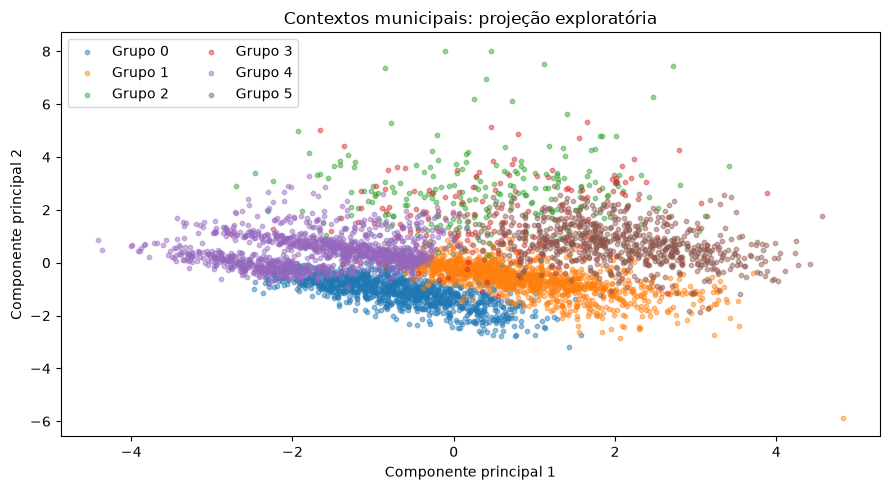

Variância explicada pelas duas componentes: 0.4871


In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

valores = artefato['pipeline'].named_steps['preparo'].transform(dados[FEATURES])
pca = PCA(n_components=2, random_state=SEMENTE)
projecao = pca.fit_transform(valores)
grupos = artefato['pipeline'].predict(dados[FEATURES])
figura, eixo = plt.subplots(figsize=(9, 5))
for grupo in sorted(np.unique(grupos)):
    mascara = grupos == grupo
    eixo.scatter(projecao[mascara, 0], projecao[mascara, 1], s=10, alpha=0.45, label=f'Grupo {grupo}')
eixo.set(xlabel='Componente principal 1', ylabel='Componente principal 2', title='Contextos municipais: projeção exploratória')
eixo.legend(ncol=2)
figura.tight_layout()
plt.show()
print('Variância explicada pelas duas componentes:', round(pca.explained_variance_ratio_.sum(), 4))

## 6. Reabertura do modelo e API REST completa

O código abaixo é o conteúdo integral de `api.py`. A API carrega o modelo uma vez na inicialização, valida entradas e nunca chama `fit` durante uma requisição. A inicialização do servidor fica protegida pelo bloco `__main__`; os exemplos seguintes usam o cliente de testes do Flask.

Rotas: `GET /saude`, `GET /modelo`, `GET /municipios/<codigo_ibge>` e `POST /prever`. O POST recebe somente `codigo_ibge` textual de sete dígitos ou `indicadores` contendo exatamente as oito features. Erros de domínio retornam 422, município ausente 404 e artefato indisponível 503.

In [10]:
"""API independente: apenas este arquivo e modelo_alpha4.joblib são necessários."""

import math
import os
from pathlib import Path

import joblib
import pandas as pd
from flask import Flask, jsonify, request
from werkzeug.exceptions import HTTPException


def validar_indicadores(indicadores, artefato):
    if not isinstance(indicadores, dict) or set(indicadores) != set(artefato['features']):
        raise ValueError('indicadores deve conter exatamente as oito features informadas em /modelo.')
    for nome, valor in indicadores.items():
        try:
            finito = isinstance(valor, (int, float)) and not isinstance(valor, bool) and math.isfinite(valor)
        except OverflowError:
            finito = False
        if not finito or valor < 0:
            raise ValueError(f'{nome} deve ser um número finito não negativo.')
        if nome in artefato['percentuais'] and valor > 100:
            raise ValueError(f'{nome} deve estar entre zero e cem.')
    if indicadores['cobertura_coleta_seletiva_pct'] > indicadores['cobertura_coleta_residuos_pct']:
        raise ValueError('A cobertura seletiva não pode superar a cobertura total.')


def criar_app(caminho_modelo=None):
    app = Flask(__name__)
    app.json.ensure_ascii = False
    app.config['MAX_CONTENT_LENGTH'] = 32 * 1024

    @app.errorhandler(HTTPException)
    def tratar_http(erro):
        return jsonify({'erro': erro.description}), erro.code

    pasta = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
    caminho = Path(caminho_modelo or os.getenv('ALPHA4_MODELO', pasta / 'modelo_alpha4.joblib'))
    # Carrega uma única vez na inicialização. Nunca há fit dentro das rotas.
    try:
        artefato = joblib.load(caminho)
        if artefato.get('formato') != 1:
            raise ValueError('Formato de modelo incompatível.')
    except Exception:
        app.logger.exception('Não foi possível carregar o modelo local.')
        artefato = None

    @app.get('/saude')
    def saude():
        return jsonify({'status': 'ok' if artefato else 'indisponivel'}), 200 if artefato else 503

    @app.get('/modelo')
    def modelo():
        if artefato is None:
            return jsonify({'erro': 'Modelo indisponível.'}), 503
        return jsonify({chave: artefato[chave] for chave in [
            'modelo', 'k', 'features', 'perfis', 'regras', 'ano_referencia', 'metricas', 'versoes',
        ]})

    def prever(indicadores, municipio=None):
        entrada = pd.DataFrame([indicadores], columns=artefato['features'])
        grupo = int(artefato['pipeline'].predict(entrada)[0])
        perfil = artefato['perfis'][str(grupo)]
        recomendacoes = [item for item in perfil['recomendacoes'] if
            item['categoria'] != 'entrega_voluntaria'
            or indicadores['pontos_entrega_voluntaria_por_mil_hab'] > 0]
        if not recomendacoes:
            recomendacoes = [{
                'categoria': 'consumo_consciente',
                'orientacao': 'Planeje compras e evite descartáveis desnecessários.',
                'motivo_grupo': 'Sugestão geral após excluir entrega voluntária sem indicador local positivo.',
            }]
        return jsonify({
            'modelo': artefato['modelo'], 'grupo': grupo, 'perfil': perfil['nome'],
            'municipio': municipio, 'ano_referencia': artefato['ano_referencia'],
            'recomendacoes': recomendacoes,
            'fora_da_faixa_observada': [nome for nome in artefato['features']
                if indicadores[nome] > artefato['limites_observados'][nome]],
            'aviso': 'Sugestões por contexto municipal de 2023, baseadas em regras de projeto; não preveem engajamento individual. Confirme serviços locais e não manipule resíduos perigosos.',
        })

    @app.get('/municipios/<codigo>')
    def consultar_municipio(codigo):
        if artefato is None:
            return jsonify({'erro': 'Modelo indisponível.'}), 503
        registro = artefato['catalogo'].get(codigo)
        if registro is None:
            return jsonify({'erro': 'Município não encontrado na base de 2023.'}), 404
        indicadores = {nome: registro[nome] for nome in artefato['features']}
        return prever(indicadores, {'codigo_ibge': codigo, 'nome': registro['municipio'], 'uf': registro['uf']})

    @app.post('/prever')
    def receber_previsao():
        if artefato is None:
            return jsonify({'erro': 'Modelo indisponível.'}), 503
        corpo = request.get_json()
        if isinstance(corpo, dict) and set(corpo) == {'codigo_ibge'}:
            codigo = corpo['codigo_ibge']
            if not isinstance(codigo, str) or len(codigo) != 7 or not codigo.isascii() or not codigo.isdigit():
                return jsonify({'erro': 'codigo_ibge deve ser um texto com sete dígitos.'}), 422
            return consultar_municipio(codigo)
        if not isinstance(corpo, dict) or set(corpo) != {'indicadores'}:
            return jsonify({'erro': 'Envie apenas codigo_ibge ou indicadores.'}), 422
        try:
            validar_indicadores(corpo['indicadores'], artefato)
        except ValueError as erro:
            return jsonify({'erro': str(erro)}), 422
        return prever(corpo['indicadores'])

    return app


app = criar_app()

In [11]:
API_CODIGO = '"""API independente: apenas este arquivo e modelo_alpha4.joblib são necessários."""\n\nimport math\nimport os\nfrom pathlib import Path\n\nimport joblib\nimport pandas as pd\nfrom flask import Flask, jsonify, request\nfrom werkzeug.exceptions import HTTPException\n\n\ndef validar_indicadores(indicadores, artefato):\n    if not isinstance(indicadores, dict) or set(indicadores) != set(artefato[\'features\']):\n        raise ValueError(\'indicadores deve conter exatamente as oito features informadas em /modelo.\')\n    for nome, valor in indicadores.items():\n        try:\n            finito = isinstance(valor, (int, float)) and not isinstance(valor, bool) and math.isfinite(valor)\n        except OverflowError:\n            finito = False\n        if not finito or valor < 0:\n            raise ValueError(f\'{nome} deve ser um número finito não negativo.\')\n        if nome in artefato[\'percentuais\'] and valor > 100:\n            raise ValueError(f\'{nome} deve estar entre zero e cem.\')\n    if indicadores[\'cobertura_coleta_seletiva_pct\'] > indicadores[\'cobertura_coleta_residuos_pct\']:\n        raise ValueError(\'A cobertura seletiva não pode superar a cobertura total.\')\n\n\ndef criar_app(caminho_modelo=None):\n    app = Flask(__name__)\n    app.json.ensure_ascii = False\n    app.config[\'MAX_CONTENT_LENGTH\'] = 32 * 1024\n\n    @app.errorhandler(HTTPException)\n    def tratar_http(erro):\n        return jsonify({\'erro\': erro.description}), erro.code\n\n    pasta = Path(__file__).resolve().parent if \'__file__\' in globals() else Path.cwd()\n    caminho = Path(caminho_modelo or os.getenv(\'ALPHA4_MODELO\', pasta / \'modelo_alpha4.joblib\'))\n    # Carrega uma única vez na inicialização. Nunca há fit dentro das rotas.\n    try:\n        artefato = joblib.load(caminho)\n        if artefato.get(\'formato\') != 1:\n            raise ValueError(\'Formato de modelo incompatível.\')\n    except Exception:\n        app.logger.exception(\'Não foi possível carregar o modelo local.\')\n        artefato = None\n\n    @app.get(\'/saude\')\n    def saude():\n        return jsonify({\'status\': \'ok\' if artefato else \'indisponivel\'}), 200 if artefato else 503\n\n    @app.get(\'/modelo\')\n    def modelo():\n        if artefato is None:\n            return jsonify({\'erro\': \'Modelo indisponível.\'}), 503\n        return jsonify({chave: artefato[chave] for chave in [\n            \'modelo\', \'k\', \'features\', \'perfis\', \'regras\', \'ano_referencia\', \'metricas\', \'versoes\',\n        ]})\n\n    def prever(indicadores, municipio=None):\n        entrada = pd.DataFrame([indicadores], columns=artefato[\'features\'])\n        grupo = int(artefato[\'pipeline\'].predict(entrada)[0])\n        perfil = artefato[\'perfis\'][str(grupo)]\n        recomendacoes = [item for item in perfil[\'recomendacoes\'] if\n            item[\'categoria\'] != \'entrega_voluntaria\'\n            or indicadores[\'pontos_entrega_voluntaria_por_mil_hab\'] > 0]\n        if not recomendacoes:\n            recomendacoes = [{\n                \'categoria\': \'consumo_consciente\',\n                \'orientacao\': \'Planeje compras e evite descartáveis desnecessários.\',\n                \'motivo_grupo\': \'Sugestão geral após excluir entrega voluntária sem indicador local positivo.\',\n            }]\n        return jsonify({\n            \'modelo\': artefato[\'modelo\'], \'grupo\': grupo, \'perfil\': perfil[\'nome\'],\n            \'municipio\': municipio, \'ano_referencia\': artefato[\'ano_referencia\'],\n            \'recomendacoes\': recomendacoes,\n            \'fora_da_faixa_observada\': [nome for nome in artefato[\'features\']\n                if indicadores[nome] > artefato[\'limites_observados\'][nome]],\n            \'aviso\': \'Sugestões por contexto municipal de 2023, baseadas em regras de projeto; não preveem engajamento individual. Confirme serviços locais e não manipule resíduos perigosos.\',\n        })\n\n    @app.get(\'/municipios/<codigo>\')\n    def consultar_municipio(codigo):\n        if artefato is None:\n            return jsonify({\'erro\': \'Modelo indisponível.\'}), 503\n        registro = artefato[\'catalogo\'].get(codigo)\n        if registro is None:\n            return jsonify({\'erro\': \'Município não encontrado na base de 2023.\'}), 404\n        indicadores = {nome: registro[nome] for nome in artefato[\'features\']}\n        return prever(indicadores, {\'codigo_ibge\': codigo, \'nome\': registro[\'municipio\'], \'uf\': registro[\'uf\']})\n\n    @app.post(\'/prever\')\n    def receber_previsao():\n        if artefato is None:\n            return jsonify({\'erro\': \'Modelo indisponível.\'}), 503\n        corpo = request.get_json()\n        if isinstance(corpo, dict) and set(corpo) == {\'codigo_ibge\'}:\n            codigo = corpo[\'codigo_ibge\']\n            if not isinstance(codigo, str) or len(codigo) != 7 or not codigo.isascii() or not codigo.isdigit():\n                return jsonify({\'erro\': \'codigo_ibge deve ser um texto com sete dígitos.\'}), 422\n            return consultar_municipio(codigo)\n        if not isinstance(corpo, dict) or set(corpo) != {\'indicadores\'}:\n            return jsonify({\'erro\': \'Envie apenas codigo_ibge ou indicadores.\'}), 422\n        try:\n            validar_indicadores(corpo[\'indicadores\'], artefato)\n        except ValueError as erro:\n            return jsonify({\'erro\': str(erro)}), 422\n        return prever(corpo[\'indicadores\'])\n\n    return app\n\n\napp = criar_app()\n\nif __name__ == \'__main__\':\n    app.run(host=\'127.0.0.1\', port=int(os.getenv(\'PORT\', \'5000\')), debug=False)\n'
Path('api.py').write_text(API_CODIGO, encoding='utf-8', newline='\n')
print('api.py gerado com o código completo mostrado nesta célula.')

api.py gerado com o código completo mostrado nesta célula.


In [12]:
reaberto = joblib.load('modelo_alpha4.joblib')
assert np.array_equal(reaberto['pipeline'].predict(dados[FEATURES]), artefato['pipeline'].predict(dados[FEATURES]))
namespace = {'__name__': 'alpha4_api_notebook', '__file__': str(Path('api.py').resolve())}
exec(compile(API_CODIGO, 'api.py', 'exec'), namespace)
cliente = namespace['app'].test_client()
resposta = cliente.post('/prever', json={'codigo_ibge': '1100015'})
assert resposta.status_code == 200
display(resposta.json)
assert cliente.post('/prever', json={'indicadores': {}}).status_code == 422
print('Modelo reaberto e previsão HTTP validados sem retreinar.')

{'ano_referencia': 2023,
 'aviso': 'Sugestões por contexto municipal de 2023, baseadas em regras de projeto; não preveem engajamento individual. Confirme serviços locais e não manipule resíduos perigosos.',
 'fora_da_faixa_observada': [],
 'grupo': 4,
 'modelo': 'kmeans',
 'municipio': {'codigo_ibge': '1100015',
  'nome': "Alta Floresta D'Oeste",
  'uf': 'RO'},
 'perfil': 'Grupo 4: coleta seletiva média 3.4%',
 'recomendacoes': [{'categoria': 'reducao_e_reutilizacao',
   'motivo_grupo': 'Média de cobertura_coleta_seletiva_pct: 3.42; regra < 30.',
   'orientacao': 'Reduza descartáveis e reutilize materiais limpos e seguros.'},
  {'categoria': 'separacao_e_educacao',
   'motivo_grupo': 'Média de recuperacao_reciclaveis_pct: 0.89; regra < 5.',
   'orientacao': 'Aprenda a separar recicláveis e compartilhe orientações locais verificadas.'},
  {'categoria': 'entrega_voluntaria',
   'motivo_grupo': 'Média de pontos_entrega_voluntaria_por_mil_hab: 0.03; regra > 0.',
   'orientacao': 'Consulte 

Modelo reaberto e previsão HTTP validados sem retreinar.


## 7. Discussão dos resultados e limites

Os números e perfis calculados acima devem ser interpretados como contexto ambiental municipal. O agrupamento não produz um rótulo verdadeiro de “melhor missão”. A associação a categorias vem das regras auditáveis, e não de aprendizado de preferências individuais.

- Os dados declarados podem conter extremos e erros não detectados; a transformação logarítmica reduz influência, mas não garante eliminar esse problema.
- A base contém apenas municípios respondentes válidos e usa 2023 como referência ambiental. Não inferimos indicadores ausentes de municípios não representados.
- A partição aleatória por região não mede generalização temporal ou para estados inteiramente novos.
- Há somente uma divisão com semente fixa e uma faixa pequena de k. O vencedor é o melhor entre esses candidatos, não um ótimo global comprovado.
- Não há avaliação humana das recomendações, teste A/B, dado de missão aceita ou evidência causal de mudança de hábitos. Esses são próximos passos, junto de atualização da base.
- Nenhuma missão deve incentivar manipular resíduos perigosos ou entrar em áreas de descarte.

Referências técnicas: [avaliação de agrupamentos scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation), [misturas gaussianas](https://scikit-learn.org/stable/modules/mixture.html) e [testes Flask](https://flask.palletsprojects.com/en/stable/testing/).